# 04. Mystery, Espionage & Social Deduction — A Visual, Concept-First Guide

> 💡 **Read This Like an Illustrated Article (No Code Required!)**  
> **All heavy code has been tucked away** into a companion helper module ([`_mystery_demo.py`](_mystery_demo.py)), and every code cell below is **collapsed by default** and reduced to a single line.  
> - **Just want to understand what `canonarc` can do?** Scroll straight through the explanations and live visual outputs below.  
> - **Curious how a feature is coded?** Open any **"💻 Peek at the `canonarc` API"** dropdown to see the tiny 5–10 line core snippet, or click [`_mystery_demo.py`](_mystery_demo.py) to inspect the full implementation.

---

## 1. How the Mystery & Social Deduction Domain Works

Whether you are building a **detective game**, an **espionage thriller**, a **tabletop RPG intrigue campaign**, or a **social deduction game** (*Werewolf*, *Mafia*, *Among Us*, *Blood on the Clocktower*), the entire genre runs on one core mechanic: **information asymmetry**—who knows what, who is wearing a mask, who is faking a smile, and who believes a lie.

In a normal AI chatbot or standard RAG/GraphRAG system, there is only **one shared memory** (the "omniscient" world state). If you hand that memory to an AI playing a detective, **the game breaks immediately**:

| Classic Mystery Problem | What Goes Wrong in Standard AI / RAG | What *Should* Happen Instead |
| :--- | :--- | :--- |
| **1. Mind-Reading Detectives** | Telling the AI *"pretend you don't know Vance is the thief"* fails—the secret is in the prompt, so the detective still acts suspicious or slips up. | Secrets the detective doesn't know should **never enter the prompt at all**. |
| **2. Unmasked Spies** | A villain in disguise (`The Velvet Courier`) leaks their true name (`Lord Vance`) or private goal (`steal_royal_cipher`). | Fooled characters see **only the disguise persona**—never the real identity or secret connections. |
| **3. Fake Smiles (Facades)** | A traitor who acts warm and helpful leaks their hidden hatred (`hostile`), ruining the twist. | Fooled characters see **only the outward act**; the hidden hostility stays concealed until unmasked. |
| **4. Lies & Cover Stories** | Even if a character was lied to, semantic search ("vault lock") still pulls up the true crime memory. | A deceived character's memory search runs against **their lie**, never the ground truth. |
| **5. Outdated Beliefs & Hidden Causes** | A detective somehow "knows" an NPC was kidnapped across town, or notices someone is "tense" and magically knows *why*. | Characters keep their **outdated belief** until told otherwise, and see observable clues (`tense`) with the secret reason blanked out. |
| **6. Shared Group Scenes** | Two characters talk in a room—one knows a secret, one doesn't—and the AI accidentally blends their knowledge. | The engine cleanly separates **"what at least one person knows"** (dramatic irony) from **"safe common ground"** (what *everyone* in the room knows). |

---

## 2. How `canonarc` Implements This at a High Level

Instead of maintaining five messy, error-prone copies of your story world (one per character), `canonarc` uses a simple, powerful mental model:

> **One Authoritative Game Master's Binder (Ground Truth) + Per-Character Sunglasses (POV Projection)**

1. **You record what *actually* happened once** in the Ground-Truth World Graph (who is disguised, who witnessed an event, who was lied to, who is faking friendliness).
2. **Before any AI character speaks or thinks**, you ask `canonarc` for that character's **Point of View (POV)**.
3. **`canonarc` projects the world through that character's lens**—automatically masking disguises, hiding private thoughts, swapping hidden hostility for polite facades, replacing true crime memories with cover stories, and stripping secret reasons.
4. **The LLM only ever sees the filtered view.** Because forbidden secrets are physically absent from the prompt, accidental metagaming becomes **structurally impossible**.

```mermaid
flowchart LR
    GT["🏛️ Ground-Truth World<br/>(The Game Master's Binder)<br/>• True identities &amp; disguises<br/>• Real feelings vs. fake smiles<br/>• What really happened + who was lied to"]
    LENS{"🕶️ POV Filter<br/>'What can THIS character see?'"}

    P1["🕵️ Detective Clara (Fooled)<br/>• Sees 'The Velvet Courier' (masked)<br/>• Sees Mira's polite smile only<br/>• Believes the archivist cover story"]
    P2["🤝 Accomplice Mira (Insider)<br/>• Knows Vance is behind the mask<br/>• Remembers the real vault theft<br/>• Still can't read Vance's private mind"]
    P3["💬 Safe Common Ground<br/>(Clara ∩ Mira)<br/>• Only facts BOTH know<br/>• Zero risk of accidental leaks"]
    P4["🎭 Game Master View<br/>• Sees everything + who is in the dark<br/>• Great for narrators &amp; debugging"]

    GT --> LENS
    LENS --> P1
    LENS --> P2
    LENS --> P3
    LENS --> P4
```

### The 6-Layer Memory Model (Translated to Plain English)

Whenever you hear `canonarc` mention "Tiers 1–6", think of it as a **6-drawer filing cabinet** for your story world:

| Layer | Plain-English Name | What It Stores in a Mystery Game |
| :--- | :--- | :--- |
| **Tier 1** | **Who's Who & Disguises** | Canonical identities (`Lord Vance`), nicknames (`Vance`), and scoped disguises (`The Velvet Courier` + who can see through it). |
| **Tier 2** | **Character Traits & Secrets** | Observable traits (`mood: tense`, `location`) vs. hidden `private_state` (`agenda: steal_royal_cipher`) that only the Game Master sees. |
| **Tier 3** | **Relationships & Fake Smiles** | True feelings (`stance`), outward acts (`facade`), outdated beliefs about others (`belief_state`), and item ownership (`possesses`). |
| **Tier 4** | **Current Scene** | Who is in the room right now and what is being talked about. |
| **Tier 5** | **Speaking Style (Voice Bank)** | Sample dialogue lines tagged by disguise persona and outward tone so a spy sounds charming in public and cold in private. |
| **Tier 6** | **Memories, Lies & Amnesia** | Past events (`episodes`) tagged per character as *witnessed*, *told*, *deceived* (with a cover story), *forgotten*, or *suppressed*. |

---

## 3. Meet the Cast of *"The Velvet Cipher"*

Throughout this walkthrough, we will play out a candlelit masquerade heist with five characters:

| Character | Public Role | Secret Reality |
| :--- | :--- | :--- |
| **🕵️ Detective Clara** | Lead investigator at the masquerade | Fooled by Vance's disguise, charmed by Mira's fake smile, and fed a cover story about the missing cipher. |
| **🎭 Lord Vance** | Disguised as **The Velvet Courier** | The mastermind who picked the vault lock, stole the Royal Cipher, and locked Henrik in the wine cellar. |
| **🤝 Mira** | Helpful, polite banquet guest | Vance's lookout. Unmasked, but wearing a warm social **facade** to hide her hostility toward Clara. |
| **📚 Archivist Henrik** | Keeper of the Royal Cipher | Ambushed by Vance, locked in the cellar, and given a hypnotic tonic that **suppresses** his memory of the attack. |
| **🛡️ Captain Brandt** | Head of palace security | Tipped off about the theft (`told`), but drugged so he **forgets** glimpsing the Velvet Courier leaving the vault corridor. |

Let's initialize the demo environment below (1 hidden setup call).

In [1]:
#@title ⚙️ Initialize Demo Session (click to inspect)
import sys
from pathlib import Path

sys.path.insert(0, str(Path("examples").resolve() if Path("examples/_mystery_demo.py").exists() else Path.cwd()))
import _mystery_demo as demo

session = demo.MysteryDemoSession()


---

## Step 1: The #1 Bug in AI Mysteries — Mind-Reading Detectives (Live A/B Proof)

### The Domain Problem
Many beginners try to build an AI mystery by putting the whole story state into the prompt and adding a rule like: *"Remember, Detective Clara doesn't know Lord Vance stole the cipher—pretend she doesn't know!"*

In practice, LLMs **leak anyway**. Because the secret words (`Lord Vance`, `vault`, `picked the lock`) are sitting right inside the prompt's attention window, the model subtly steers the detective toward the vault or makes her inexplicably suspicious.

### How `canonarc` Solves It
Instead of asking the AI to *ignore* secrets, `canonarc` **removes them before the prompt is built**. We run the exact same interrogation scene twice with the same LLM:
- **Condition A (Omniscient Prompt):** The AI sees the full world state plus a polite instruction not to spoil secrets.
- **Condition B (`canonarc` POV Projection):** We pass `pov_entity_ids=["char_clara"]`. `canonarc` swaps `Lord Vance` → `The Velvet Courier`, strips his private agenda, and replaces the vault theft with Clara's cover story (*"misplaced by the archivist"*).

**👀 What to look for below:** Compare the red card (left) vs. the green card (right). Notice how Condition A leaks vault details or uncanny suspicion, while Condition B naturally asks about the *archivist*—making secret leaks **structurally impossible**.

<details>
<summary>💻 Peek at the <code>canonarc</code> API used in Step 1 (full code in <a href="_mystery_demo.py"><code>_mystery_demo.py</code></a>)</summary>

```python
# Condition A: Omniscient (GM) view — exposes every secret
omni_ctx = engine.retrieve_context(step=15, text=scene, pov_entity_ids=None)

# Condition B: Filtered strictly to Detective Clara's knowledge
clara_ctx = engine.retrieve_context(step=15, text=scene, pov_entity_ids=["char_clara"])

# Format either context directly into an LLM system prompt
prompt_block = engine.format_context(clara_ctx)
```
</details>

In [2]:
#@title 🔬 Step 1: Run Omniscient vs. canonarc POV A/B Proof
session.run_step1_ab_metagaming_proof()


---

## Step 2: Building the Masquerade — Four Types of Secrecy Working Together

### The Domain Problem
Real mysteries don't have just one kind of secret. At the same party, a detective can be fooled in **four completely different ways** at once:
1. **A Masked Stranger (Disguise):** You don't know *who* this person really is.
2. **A Two-Faced Ally (Facade vs. True Stance):** You know *who* they are, so they can't hide behind a mask—instead, they smile to your face while secretly hating you.
3. **Outdated Information (Stale Belief):** Something happened off-screen (Henrik was locked in the cellar), so your mental picture of him is now out of date.
4. **An Unexplained Clue (Observable Tell, Hidden Cause):** You can clearly *see* Mira looks nervous (`mood: tense`), but you shouldn't magically know *why* she's nervous (*"she just kept watch at the vault"*).

### How `canonarc` Implements These Four Boundaries
Notice one clever design rule under the hood: when a character is **masked** (like Vance → `masked:char_vance`), `canonarc` strips *all* relationship edges attached to their real ID so an AI can't deduce who is behind the mask by looking at their social graph! That's why we demonstrate disguises on **Lord Vance** and fake smiles on **unmasked Mira**:

```mermaid
graph TD
    subgraph GroundTruth["🎭 Ground Truth (What Really Exists)"]
        V["Lord Vance<br/>private: steal_royal_cipher"] -. "disguise: The Velvet Courier" .-> VC["Persona"]
        M["Mira (mood: tense)<br/>reason: Watched vault lock"] -- "stance: hostile (-0.85)" --> C1["Detective Clara"]
        M == "facade: helpful (+0.75)" ==> C1
        H["Archivist Henrik<br/>status: incapacitated @ cellar"]
    end
    subgraph ClaraLens["🕵️ Detective Clara's Filtered POV"]
        MV["The Velvet Courier<br/>(masked:char_vance)"]
        M2["Mira (mood: tense)<br/>reason: [REDACTED]"] == "facade: helpful (+0.75)" ==> C2["Detective Clara"]
        H2["Archivist Henrik<br/>status: alive @ library<br/>(stale belief_state)"]
    end
```

**👀 What to look for below:** Compare **Clara's POV (left)** with the **Omniscient GM View (right)** at Step 13. Check all four boundaries side by side:
- Vance appears as `masked:char_vance` (`The Velvet Courier`) with zero private state.
- Mira shows **only** her `[facade]` (`helpful`, `trust: 0.75`)—her hostile `stance` is gone.
- Mira's `mood: tense` is visible as a clue, but the secret `reason` (*"Kept watch..."*) is completely redacted.
- Henrik still shows `status: alive` for Clara, while the GM sees `status: incapacitated`.

<details>
<summary>💻 Peek at the <code>canonarc</code> API used in Step 2 (full code in <a href="_mystery_demo.py"><code>_mystery_demo.py</code></a>)</summary>

```python
# 1. Scoped Disguise (only Vance & Mira can see through it)
AliasRecord(alias="The Velvet Courier", entity_id="char_vance",
            kind="disguise", known_to=["char_vance", "char_mira"],
            persona_name="The Velvet Courier")

# 2. Fake Smile (facade) hiding real hostility (stance)
EdgeDelta(source_id="char_mira", target_id="char_clara", relation_type="stance", state={"tone": "hostile", "trust": -0.85})
EdgeDelta(source_id="char_mira", target_id="char_clara", relation_type="facade", state={"tone": "helpful", "trust": 0.75})

# 3. Stale Belief override (Clara still thinks Henrik is alive in the library)
EdgeDelta(source_id="char_clara", target_id="char_archivist", relation_type="belief_state",
          state={"status": "alive", "location_id": "loc_library"})

# 4. Observable clue with secret causal provenance (auto-redacted if observer didn't witness the episode)
EntityDelta(entity_id="char_mira", state={"mood": "tense"},
            caused_by_episode_id="ep_step12_cipher_theft",
            reason="Kept watch while Vance picked the vault lock")
```
</details>

In [3]:
#@title 🏗️ Step 2: Seed Masquerade & Compare Clara's POV vs. GM View
session.run_step2_seed_masquerade()


---

## Step 3: How Memories, Lies & Amnesia Work (All 5 Epistemic Modes)

### The Domain Problem
In a mystery, characters don't just either "know" or "not know" an event. Information travels and degrades in **five distinct ways**:

| Mode | Plain-English Meaning | Example in *"The Velvet Cipher"* |
| :--- | :--- | :--- |
| **`direct`** | Saw it with their own eyes | **Vance & Mira** carried out the vault theft. |
| **`told`** | Learned it secondhand | **Captain Brandt** gets tipped off by a palace informant. |
| **`deceived`** | Fed a fabricated cover story | **Clara** is told *"the archivist accidentally misplaced the cipher."* |
| **`forgotten`** | Natural memory loss or drugged stupor | Mira slips a sedative into **Brandt's** wine, so he forgets seeing the Courier leave the vault corridor. |
| **`suppressed`** | Magical, hypnotic, or forced memory wipe | **Henrik** is given a hypnotic tonic that erases his memory of the wine-cellar ambush. |

### How `canonarc` Prevents "Search Engine Leaks" (Vector Isolation)
A subtle bug in almost every vector-database RAG system: even if you swap a character's memory text to a cover story, **the vector embedding is still computed from the secret ground truth**. So if someone queries `"vault lock stolen"`, the vector search still matches the secret!

`canonarc` fixes this at the embedding level: for any `deceived` character, `canonarc` indexes and searches **their `believed_summary`**, not the true event. And for `forgotten` or `suppressed` events, the episode is completely invisible to that character's queries.

**👀 What to look for below:**
1. The **Epistemic Knowledge Matrix** shows all 5 characters × 3 major secrets + Vance's disguise status at Step 20—computed live by querying each character's POV.
2. The green **Vector Isolation** badge confirms that querying Clara's memory with secret keywords (`"vault lock stolen royal cipher"`) returns **0 ground-truth leaks**.

<details>
<summary>💻 Peek at the <code>canonarc</code> API used in Step 3 (full code in <a href="_mystery_demo.py"><code>_mystery_demo.py</code></a>)</summary>

```python
# Feed Clara a cover story (deceived)
InformDelta(episode_id="ep_step12_cipher_theft", entity_id="char_clara",
            epistemic="deceived",
            believed_summary="The royal cipher was accidentally misplaced by the archivist.")

# Tip off Brandt (told), then make him forget the corridor glimpse (forgotten)
engine.inform_entity(step=16, episode_id="ep_step12_cipher_theft", entity_id="char_guard", epistemic="told")
engine.inform_entity(step=17, episode_id="ep_step14_courier_glimpse", entity_id="char_guard", epistemic="forgotten")

# Wipe Henrik's memory of the cellar ambush (suppressed)
engine.inform_entity(step=18, episode_id="ep_step15_cellar_ambush", entity_id="char_archivist", epistemic="suppressed")
```
</details>

In [4]:
#@title 🧠 Step 3: Run 5-Mode Epistemic Lifecycle & Render Knowledge Matrix
session.run_step3_epistemic_modes()


Observer POV,Vance Disguise,Vault Theft (Step 12)ep_step12_cipher_theft,Corridor Glimpse (Step 14)ep_step14_courier_glimpse,Cellar Ambush (Step 15)ep_step15_cellar_ambush
Detective Clara,MASKED,DECEIVEDBelieves: archivist misplaced cipher,IGNORANT,IGNORANT
Lord Vance,PIERCED,DIRECT,DIRECT,DIRECT
Mira,PIERCED,DIRECT,IGNORANT,IGNORANT
Captain Brandt,MASKED,TOLDHeard secondhand,FORGOTTENDrugged wine @ Step 17,IGNORANT
Archivist Henrik,MASKED,IGNORANT,IGNORANT,SUPPRESSEDHypnotic tonic @ Step 18


---

## Step 4: Group Scenes — Dramatic Irony vs. Safe Common Ground

### The Domain Problem
What happens when **two characters with very different secrets** share a scene—for example, Detective Clara (fooled) and Mira (secret accomplice) standing side by side watching The Velvet Courier walk across the ballroom?

Depending on what you're generating, you need one of two opposite views:
- **Writing a third-person thriller narration?** You want **Dramatic Irony**—the narrator should know Mira recognizes Vance *and* explicitly know that Clara is still in the dark.
- **Generating shared dialogue or a public town-hall recap?** You need **Strict Common Ground**—only facts that *both* Clara and Mira know, so nobody accidentally blurts out a secret.

### How `canonarc` Solves It (`pov_mode="any"` vs. `"all"`)
When you pass multiple characters (`pov_entity_ids=["char_clara", "char_mira"]`), `canonarc` lets you pick the exact projection rule:
- **`pov_mode="any"` (Union):** Includes anything known by *at least one* person in the group, and automatically adds **`| ignorant: char_clara`** tags so the narrator knows who doesn't know!
- **`pov_mode="all"` (Intersection):** Keeps **only** what *every* listed character knows. Vance stays masked, the secret midnight pact disappears, and private thoughts are stripped.

**👀 What to look for below:** Compare the 3 side-by-side cards (`"any"` vs. `"all"` vs. Omniscient GM). Notice how `"all"` produces a clean, zero-leak shared floor!

<details>
<summary>💻 Peek at the <code>canonarc</code> API used in Step 4 (full code in <a href="_mystery_demo.py"><code>_mystery_demo.py</code></a>)</summary>

```python
# Union: dramatic irony for third-person narration (includes "| ignorant: char_clara")
ctx_any = engine.retrieve_context(step=20, text=scene, pov_entity_ids=["char_clara", "char_mira"], pov_mode="any")

# Intersection: strict common ground safe for shared dialogue (zero leaks!)
ctx_all = engine.retrieve_context(step=20, text=scene, pov_entity_ids=["char_clara", "char_mira"], pov_mode="all")
```
</details>

In [5]:
#@title 🔀 Step 4: Compare Multi-POV "any" vs. "all" vs. Omniscient GM
session.run_step4_multi_pov()


---

## Step 5: Keeping a Spy's Voice in Character (Tier 5 Voice Bank)

### The Domain Problem
Hiding *facts* isn't enough if a character's **tone of voice** gives them away!
- In private with Mira, **Lord Vance** is cold and ruthless (*"if she reaches the conservatory bust, burn the ledger"*).
- In public as **The Velvet Courier**, he must sound theatrical and charming (*"A masquerade thrives on mystery, Detective..."*).
- Likewise, **Mira** should pull polite, helpful speech examples when talking to Clara under her `[facade]`—never her hostile private lines!

### How `canonarc` Solves It
`canonarc`'s **Tier 5 Voice Bank** automatically filters dialogue examples (`VoiceExemplar`) using the active POV:
1. **Disguise Persona Matching:** When Vance is masked (`masked:char_vance`), only lines tagged with `persona="The Velvet Courier"` are eligible, and the speaker ID stays masked so the true ID never leaks.
2. **Facade-First Tone Matching:** For Mira → Clara, the Voice Bank prioritizes her outward `[facade]` (`formal`, `helpful`) over her hidden `stance` (`informal`, `hostile`).

**👀 What to look for below:** Only the charming courier line and Mira's polite line are selected for Clara's scene—**zero** conspirator lines leak through!

<details>
<summary>💻 Peek at the <code>canonarc</code> API used in Step 5 (full code in <a href="_mystery_demo.py"><code>_mystery_demo.py</code></a>)</summary>

```python
# Store both public-persona and private-conspirator dialogue samples
engine.commit_step(step=19, exemplars=[
    VoiceExemplar(step=19, speaker_id="char_vance", addressee_id="char_clara",
                  text="A masquerade thrives on mystery, Detective...",
                  metadata={"persona": "The Velvet Courier", "register": "formal", "tone": "charming"}),
    VoiceExemplar(step=19, speaker_id="char_vance", addressee_id="char_mira",
                  text="Keep the detective busy, Mira; if she reaches the conservatory bust, burn the ledger.",
                  metadata={"register": "informal", "tone": "hostile"}),
])

# Retrieve for Clara's POV — automatically picks ONLY the Velvet Courier persona line
ctx = engine.retrieve_context(step=20, text=scene, pov_entity_ids=["char_clara"], top_k_voice=1)
```
</details>

In [6]:
#@title 🎭 Step 5: Verify Persona & Facade-Driven Voice Bank Selection
session.run_step5_voice_bank()


---

## Step 6: Playing a Mini Social Deduction Loop (*Clues → Votes → Unmasking*)

### The Domain Problem
In social deduction games (*Werewolf*, *Mafia*, murder-mystery dinners), characters go through repeated rounds of **secret night actions**, **clue discovery**, and **public voting**—and each agent must vote based *strictly on what they personally know at that turn*.

Let's watch our cast vote across **three rounds** as the mystery unfolds:
1. **Day 1 (Step 22):** Clara is still deceived, so she wants to question the archivist. Brandt knows *Lord Vance* stole the cipher (`told`), but because he `forgot` the corridor sighting, he doesn't realize Vance is standing right next to him in disguise! Meanwhile, Vance and Mira deflect blame onto Henrik.
2. **Day 2 (Step 26 — Clue Found):** Clara discovers a torn velvet cufflink outside the vault. Her suspicion spikes and she now suspects **The Velvet Courier**, *yet his true identity is still masked*.
3. **Day 3 (Step 31 — Unmasking!):** At Step 30, Clara catches Vance red-handed. In one clean commit, `canonarc`:
   - **Pierces the disguise** (adds `char_clara` to `known_to`),
   - **Shatters Vance's facade** (removes the `facade` edge so his true hostile `stance` is exposed),
   - **Updates Clara's stale belief** about Henrik (`incapacitated` in the cellar), and
   - **Replaces her deception with the truth** (`epistemic="told"`).

**👀 What to look for below:**
1. The **3-Round Ballot Table** showing how each character's vote evolves strictly from their own POV.
2. The **Trust vs. Suspicion Chart** showing the dramatic gap between Vance's **Perceived Trust (blue)** and **True Hidden Stance (dashed red)**—until the vertical **Disguise Pierced** line where the facade shatters and Perceived Trust plummets to match reality!

<details>
<summary>💻 Peek at the <code>canonarc</code> API used in Step 6 (full code in <a href="_mystery_demo.py"><code>_mystery_demo.py</code></a>)</summary>

```python
# Unmask Vance for Clara, shatter his facade, update Henrik's belief, and reveal the theft
engine.commit_step(step=30, delta=StepDelta(
    entities=[EntityDelta(entity_id="char_vance", add_aliases=[
        AliasRecord(alias="The Velvet Courier", entity_id="char_vance",
                    kind="disguise", known_to=["char_vance", "char_mira", "char_clara"])
    ])],
    edges=[
        EdgeDelta(source_id="char_vance", target_id="char_clara", relation_type="facade", remove=True),
        EdgeDelta(source_id="char_clara", target_id="char_archivist", relation_type="belief_state",
                  state={"status": "incapacitated", "location_id": "loc_cellar"}),
    ],
    inform=[InformDelta(episode_id="ep_step12_cipher_theft", entity_id="char_clara", epistemic="told")],
))
```
</details>

Round,Agent POV,Decision / Vote,Epistemic Basis
Day 1 (Step 22),Detective Clara,Question → Archivist Henrik,Deceived by archivist cover story
Day 1 (Step 22),Captain Brandt,Accuse → Lord Vance (whereabouts unknown; courier unlinked),"Told Lord Vance stole cipher, but forgot corridor sighting"
Day 1 (Step 22),Mira (Conspirator),Deflect → Archivist Henrik,Conspirator knows truth; protects cover story
Day 1 (Step 22),Lord Vance (Conspirator),Deflect → Archivist Henrik,Conspirator knows truth; protects cover story
Day 2 (Step 26),Detective Clara,Suspect → The Velvet Courier (identity unknown),Cufflink clue raises suspicion; true name still masked
Day 2 (Step 26),Captain Brandt,Accuse → Lord Vance (whereabouts unknown; courier unlinked),"Told Lord Vance stole cipher, but forgot corridor sighting"
Day 2 (Step 26),Mira (Conspirator),Deflect → Archivist Henrik,Conspirator knows truth; protects cover story
Day 2 (Step 26),Lord Vance (Conspirator),Deflect → Archivist Henrik,Conspirator knows truth; protects cover story
Day 3 (Step 31 — Post-Unmasking),Detective Clara,Accuse → Lord Vance (The Velvet Courier),Disguise pierced + vault theft confirmed
Day 3 (Step 31 — Post-Unmasking),Captain Brandt,Accuse → Lord Vance (whereabouts unknown; courier unlinked),"Told Lord Vance stole cipher, but forgot corridor sighting"


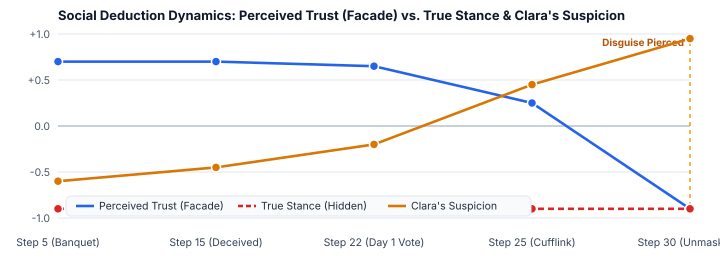

In [7]:
#@title 🗳️ Step 6: Run 3-Round Social Deduction Loop & Plot Trust/Suspicion Chart
session.run_step6_social_deduction_loop()


---

## Step 7: Non-Linear Time — Flashbacks, "What-If" Branches & Instant Undo

### The Domain Problem
Mystery stories and interactive games rarely move in a straight line:
- **Flashbacks:** A detective mentally replays an earlier clue (*"Wait—remember how he toasted me at the banquet?"*). In a naive system, writing that flashback accidentally resets Clara's *present-day* mood back to `"unsuspecting"`!
- **Branching Investigations ("What If?"):** Game designers and players love exploring alternate leads from the same checkpoint (*"What if I confront him in the ballroom vs. quietly search the conservatory?"*).
- **Instant Rewind:** If a Game Master accidentally leaks a spoiler or a player misclicks, you want to undo a turn instantly without corrupting the database.

### How `canonarc` Solves All Three
1. **`is_flashback=True`:** Records the flashback memory in Tier 6 while **protecting present-day character state** from being overwritten.
2. **`branch()` + `session()` + `diff_timelines()`:** Forks lightweight parallel timelines from Step 25 (`route_ballroom` vs. `route_conservatory`) and computes a clean side-by-side state diff.
3. **`rollback_to(step)`:** Rewinds a timeline back to an earlier step in **under 1 millisecond**.

**👀 What to look for below:**
- The **Timeline Branch Tree** visualizing both parallel investigation routes forked from Step 25.
- The **Diff Table** showing how Vance, Clara, and the Royal Cipher ended up in completely different states—plus confirmation that the Step 32 flashback kept Clara's mood safely `"suspicious"` and the scratch rewind took `< 1 ms`.

<details>
<summary>💻 Peek at the <code>canonarc</code> API used in Step 7 (full code in <a href="_mystery_demo.py"><code>_mystery_demo.py</code></a>)</summary>

```python
# 1. Safe flashback — logs the memory without overwriting present-day state
engine.commit_step(step=32, delta=StepDelta(is_flashback=True, ...))

# 2. Fork two "what-if" routes from Step 25 and compare their outcomes
engine.branch(at_step=25, name="route_ballroom")
engine.branch(at_step=25, name="route_conservatory")
diff = engine.diff_timelines("route_ballroom", "route_conservatory", at_step=28)

# 3. Sub-millisecond undo on a scratch branch
engine.session("scratch_rewind").rollback_to(25)
```
</details>

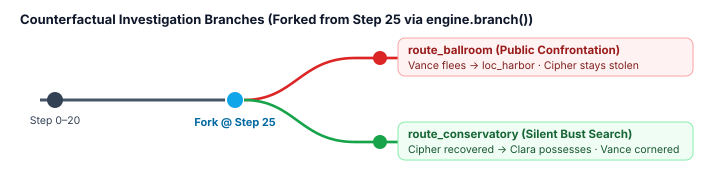

Entity,route_ballroom,route_conservatory
char_clara,"{""kind"": ""character"", ""canonical_name"": ""Detective Clara"", ""base_attributes"": {}, ""state"": {""mood"": ""frustrated"", ""location_id"": ""loc_ballroom"", ""suspicion"": 0.","{""kind"": ""character"", ""canonical_name"": ""Detective Clara"", ""base_attributes"": {}, ""state"": {""mood"": ""triumphant"", ""location_id"": ""loc_ballroom"", ""suspicion"": 0."
char_vance,"{""kind"": ""character"", ""canonical_name"": ""Lord Vance"", ""base_attributes"": {}, ""state"": {""mood"": ""fleeing"", ""location_id"": ""loc_harbor"", ""disguise"": ""The Velvet C","{""kind"": ""character"", ""canonical_name"": ""Lord Vance"", ""base_attributes"": {}, ""state"": {""mood"": ""cornered"", ""location_id"": ""loc_conservatory"", ""disguise"": ""The V"
item_royal_cipher,"{""kind"": ""item"", ""canonical_name"": ""Royal Cipher"", ""base_attributes"": {}, ""state"": {""status"": ""stolen"", ""location_id"": ""loc_ballroom""}, ""caused_by_episode_id"":","{""kind"": ""item"", ""canonical_name"": ""Royal Cipher"", ""base_attributes"": {}, ""state"": {""status"": ""recovered"", ""location_id"": ""loc_conservatory""}}"


In [8]:
#@title 🌌 Step 7: Run Flashback Safety, Counterfactual Branches & Instant Rollback
session.run_step7_time_travel_and_branches()


---

## Step 8: Automatic Story-to-Memory Extraction (No Hand-Coded Deltas!)

### The Domain Problem
So far, we've been looking at structured updates (`StepDelta`) so you could see every mechanism clearly. In a real AI game or novel pipeline, **you don't want to hand-code updates for every paragraph of story prose**—you want an LLM to read the scene and automatically figure out:
- Who witnessed the secret action (`witnesses`),
- Who was lied to (`deceived`), and
- What cover story the deceived character now believes (`believed_summary`)—without leaking the truth into it!

### How `canonarc` Solves It
We pass a fresh **Step 40** prose scene into `engine.step_transaction().extract_and_commit(...)` using DeepSeek Flash wrapped in **`CachedDeltaExtractor`** (so repeat runs are instant and free, with automatic offline fallback if no API key is set):

> *"While Captain Brandt remained in the ballroom questioning the banquet guests, Lord Vance slipped quietly into the conservatory with Mira watching the door and hid a second cipher ledger inside the hollow marble bust. Moments later, Mira returned to the ballroom and fed Captain Brandt a fabricated lead, convincing Brandt that the second cipher ledger had already been smuggled aboard a ship at the harbor docks."*

**👀 What to look for below:**
- The extraction summary card (click **"Inspect raw extracted StepDelta JSON"** if you're curious what the LLM produced).
- Side-by-side POV cards at Step 41: **Captain Brandt (left)** believes the harbor-docks lie and never sees `"hollow marble bust"` or `"conservatory"`, while the **Omniscient GM (right)** sees the full truth.

<details>
<summary>💻 Peek at the <code>canonarc</code> API used in Step 8 (full code in <a href="_mystery_demo.py"><code>_mystery_demo.py</code></a>)</summary>

```python
extractor = CachedDeltaExtractor(OpenAICompatibleExtractor.from_deepseek(), cache_dir=cache_dir)

# Read prose -> extract structured epistemic updates -> commit atomically
with engine.step_transaction(step=40, text=scene_step40) as tx:
    extracted_delta = tx.extract_and_commit(scene_step40, extractor=extractor)
```
</details>

In [9]:
#@title 🤖 Step 8: Run Live DeepSeek Flash Extraction & Verify Brandt's POV
session.run_step8_live_extraction()


---

## Step 9: 14-Point Automated Verification Scorecard

To make sure every single epistemic guarantee actually held end-to-end (not just visually!), we run a **14-point automated QA audit** powered by our `EpistemicAuditHook` flight-recorder middleware. It verifies zero secret leaks across every step, clean disguise masking & piercing, facade concealment, stale belief overrides, provenance redaction, all 5 memory modes, multi-POV projection, voice selection, flashback safety, branching, `< 1 ms` rollback, and live LLM extraction.

In [10]:
#@title ✅ Step 9: Run 14-Point Automated QA Audit & Telemetry Summary
session.run_step9_qa_audit()


Check,Status
1. A/B Live LLM Test: Zero secret leaks under canonarc POV projection,✅ PASS
2. Disguise Masking: Vance masked to masked:char_vance for fooled Clara,✅ PASS
"3. Unmasked Facade: Clara sees ONLY Mira's [facade], hidden stance concealed",✅ PASS
4. Stale belief_state: Clara projects Henrik='alive' while GM sees 'incapacitated',✅ PASS
"5. Causal Provenance Redaction: Clara sees Mira's mood='tense', reason=None",✅ PASS
6. Deceived-POV Vector Isolation: Secret-keyword query leaks 0 vault facts,✅ PASS
7. Memory Erasure (forgotten): Brandt's drugged corridor sighting invisible,✅ PASS
8. Memory Erasure (suppressed): Henrik's wiped cellar ambush invisible,✅ PASS
9. Multi-POV ('any' vs 'all'): 'any' pierces disguise; 'all' keeps masked & strips secrets,✅ PASS
"10. Tier 5 VoiceBank: Selects persona/facade exemplars, 0 conspirator lines leaked",✅ PASS


---

## 🗺️ Feature Map: When to Reach for Each `canonarc` Feature

Bookmark this cheat sheet! Whenever you design a mystery, espionage thriller, TTRPG intrigue arc, or social deduction game, look up what you need on the left to find the exact `canonarc` building block on the right:

| "In my story or game, I want to..." | `canonarc` Feature | Where to See It in Code |
| :--- | :--- | :--- |
| Stop an AI character from mind-reading secrets | `retrieve_context(..., pov_entity_ids=["char_id"])` | [`run_step1_ab_metagaming_proof`](_mystery_demo.py) |
| Hide a spy's true identity behind a disguise | `AliasRecord(..., kind="disguise", known_to=[...])` | [`run_step2_seed_masquerade`](_mystery_demo.py) |
| Give a character a fake friendly smile hiding hostility | `EdgeDelta(..., relation_type="facade")` + `relation_type="stance"` | [`run_step2_seed_masquerade`](_mystery_demo.py) |
| Keep an NPC's outdated belief about someone off-screen | `EdgeDelta(..., relation_type="belief_state")` | [`run_step2_seed_masquerade`](_mystery_demo.py) |
| Show a clue (`mood: tense`) without leaking *why* | `EntityDelta(..., caused_by_episode_id=..., reason=...)` | [`run_step2_seed_masquerade`](_mystery_demo.py) |
| Feed a character a lie that never leaks in vector search | `InformDelta(..., epistemic="deceived", believed_summary=...)` | [`run_step3_epistemic_modes`](_mystery_demo.py) |
| Erase a memory (drugged / hypnotized / forgotten) | `engine.inform_entity(..., epistemic="forgotten" \| "suppressed")` | [`run_step3_epistemic_modes`](_mystery_demo.py) |
| Narrate a group scene with dramatic irony | `retrieve_context(..., pov_entity_ids=[...], pov_mode="any")` | [`run_step4_multi_pov`](_mystery_demo.py) |
| Generate safe group dialogue with zero secret leaks | `retrieve_context(..., pov_entity_ids=[...], pov_mode="all")` | [`run_step4_multi_pov`](_mystery_demo.py) |
| Keep a spy's speaking style matching their disguise/facade | Tier 5 `VoiceExemplar` with `metadata={"persona": ...}` | [`run_step5_voice_bank`](_mystery_demo.py) |
| Unmask a villain and shatter their facade mid-game | Expand `known_to`, `remove=True` on `facade`, `epistemic="told"` | [`run_step6_social_deduction_loop`](_mystery_demo.py) |
| Replay a flashback without corrupting present-day state | `StepDelta(is_flashback=True, ...)` | [`run_step7_time_travel_and_branches`](_mystery_demo.py) |
| Explore "what-if" investigation routes or undo a turn | `engine.branch()`, `diff_timelines()`, `rollback_to()` | [`run_step7_time_travel_and_branches`](_mystery_demo.py) |
| Turn raw story prose into epistemic updates automatically | `step_transaction().extract_and_commit()` + `CachedDeltaExtractor` | [`run_step8_live_extraction`](_mystery_demo.py) |

### Want to Experiment Yourself?
- Open [`examples/_mystery_demo.py`](_mystery_demo.py) to read or tweak the cast, clues, or prompts.
- To run with a live LLM, set `DEEPSEEK_API_KEY` in `.env` at the repository root (or swap `from_deepseek()` to `from_lmstudio()` / `from_gemini()`).
- Explore the other domain walkthroughs in [`examples/README.md`](README.md) (Interactive Fiction, Literary Translation, Multi-Agent Simulation).